# 05 — Light curves

Time-series photometry is the WCC's bread and butter: transits, flares, variable stars, transients.
`wcc_etc` combines an ETC simulation with a transit model to generate a light curve with realistic
white noise.

In this notebook:
1. `TransitModel` and `LightCurveSimulator`,
2. the per-point precision, binning, and what white noise can and cannot tell you,
3. bright hosts: reads per point.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import wcc_etc
from wcc_etc import Simulation, get_scene

wcc_etc.set_wcc_style()

from wcc_etc import TransitModel, LightCurveSimulator

READS = (1, 2, 3, 6, 10, 30, 60, 120, 240)

def choose_reads(sim, t, reads=READS, **kw):
    """Smallest read count whose per-frame image has no saturated pixel; (None, last result) if none works."""
    for n in reads:
        r = sim.get_image_snr(t, n_reads=n, warn=False, **kw)
        if not np.any(r["saturated"]):
            return n, r
    return None, r

***
## 1. A transit light curve

`TransitModel` takes the usual parameters (`per` in days, `rp` = $R_p/R_*$, `a` = $a/R_*$,
`inc` in degrees, quadratic limb darkening `u`). `LightCurveSimulator.simulate(time, t_exp)`
evaluates the model at the given times (days) and adds noise from the ETC SNR at `t_exp` seconds.

[wcc_etc] note: even n_pixels is rounded up by 1 to center the PSF peak (shown once).


LightCurve(n=346, snr=222.8, flux_err=0.00449, exptime=60s)


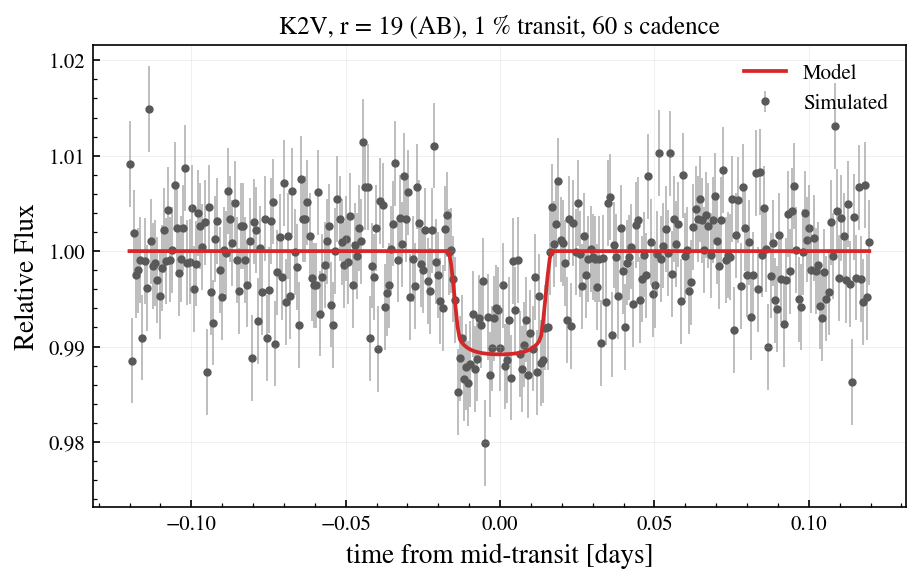

In [2]:
sim = Simulation.from_sensorfilter("zwo:r", get_scene("K2V", mag=19, bandpass="sdss_r", magsys="abmag"))
planet = TransitModel(t0=0.0, per=1.0, rp=0.1, a=10.0, inc=88.0)
t_exp = 60
time = np.arange(-0.12, 0.12, t_exp / 86400)          # days, one point per exposure
lc = LightCurveSimulator(sim, planet).simulate(time, t_exp, seed=3)
print(lc)
fig, ax = lc.plot()
ax.set(xlabel="time from mid-transit [days]", title=f"K2V, r = 19 (AB), 1 % transit, {t_exp} s cadence")
plt.show()

`lc.flux_err` is the ETC's 1 sigma per point; `flux_clean` is the noiseless model. The out-of-transit
scatter should reproduce `flux_err`, and binning should average it down as $1/\sqrt{N}$: the
simulator has only white noise. (With ~260 out-of-transit points the comparison is itself noisy at
the 10 to 20 % level; try another `seed`.) Real data have a red-noise floor (flat field, intrapixel
sensitivity × jitter, gain drift) that this ETC does not model.

In [3]:
oot = np.abs(lc.time) > 0.03                            # out of transit
resid = lc.flux[oot] - lc.flux_clean[oot]
print(f"per-point: scatter {resid.std() * 1e6:.0f} ppm, ETC flux_err {lc.flux_err * 1e6:.0f} ppm")
for nbin in (3, 10, 30):
    n = resid.size // nbin
    binned = resid[:n * nbin].reshape(n, nbin).mean(axis=1)
    print(f"binned x{nbin:3d} ({nbin * t_exp / 60:4.0f} min): scatter {binned.std() * 1e6:5.0f} ppm, white-noise expectation {lc.flux_err / np.sqrt(nbin) * 1e6:5.0f} ppm")

per-point: scatter 4742 ppm, ETC flux_err 4489 ppm
binned x  3 (   3 min): scatter  2662 ppm, white-noise expectation  2591 ppm
binned x 10 (  10 min): scatter  1655 ppm, white-noise expectation  1419 ppm
binned x 30 (  30 min): scatter   952 ppm, white-noise expectation   819 ppm


> 🤖 **Ask Jupyter AI:** *Fit the transit depth to lc.flux with scipy.optimize.curve_fit, using a box model (constant out of transit, constant minus depth inside |t| < T14/2) with T14 fixed to 0.8 h, and report the depth with its uncertainty.*
>
> Compare the uncertainty with flux_err / sqrt(N_in) : nothing more sophisticated is needed to understand exercise 2.

***
## 2. Bright hosts: reads per point

`LightCurveSimulator` uses one read per point, so a host brighter than r ~ 18 saturates it. For
those, plan with the ETC directly: `choose_reads` gives the smallest split and its per-point SNR,
and the precision is `1e6 / snr` ppm. (Notebook 02 made the plot; exercise 2 turns it into
detection significances.)

In [4]:
t_exp = 60
for m in (12, 14, 16, 18):
    sim.update(source__mag=float(m))
    n, r = choose_reads(sim, t_exp)
    print(f"K2V r = {m}: {n:3d} x {t_exp / n:5.2f} s per point, {1e6 / r['snr']:5.0f} ppm per point, {1e6 / r['snr'] / np.sqrt(60):4.0f} ppm per hour (white noise)")

K2V r = 12: 240 x  0.25 s per point,   178 ppm per point,   23 ppm per hour (white noise)
K2V r = 14:  60 x  1.00 s per point,   448 ppm per point,   58 ppm per hour (white noise)
K2V r = 16:   6 x 10.00 s per point,  1123 ppm per point,  145 ppm per hour (white noise)
K2V r = 18:   1 x 60.00 s per point,  2822 ppm per point,  364 ppm per hour (white noise)


***
## Summary

```python
planet = TransitModel(t0=0, per=1.0, rp=0.1, a=10, inc=88)
lc = LightCurveSimulator(sim, planet).simulate(time_days, t_exp_s, seed=1)   # .time .flux .flux_clean .flux_err .plot()
```

Next: [06 — fields and photometry](06_fields_and_photometry.ipynb), where whole detector frames
are rendered from Gaia.